### A.I.1 — Data acquisition

Acquire the 20 data points assigned to your group.

In [1]:
import pandas as pd
import numpy as np
from itertools import cycle
import matplotlib.pyplot as plt


group_number = 14
df = pd.read_excel('Data Take Home Assignment 1 Exercise A.xlsx')
data = df.iloc[(group_number-1)*20 : group_number*20]
print(len(data))
a = 1

20


### A.I.2 — Data transformation

Transform the acquired data, report the transformed data, and justify the choice.

In [ ]:
#X mean is 22.52 +- 8.33 and Y mean is 450.24 +- 18.68
#The inspection of the data revealed that it is not bounded by the fixed ceiling. 
#Knowing this and that centering and scaling is favourable for gradient descent’s numerical conditioning, the z-score normalization was chosen.
X = np.array(data['X'])
Y = np.array(data['Y'])
X_norm = (X - np.mean(X)) / np.std(X)
Y_norm = (Y - np.mean(Y)) / np.std(Y)

### A.I.3 — Least squares

Compute the closed-form linear regression parameters. Print them and plot the data with the regression line.

slope: -0.9751730769383196, intercept: -2.7063866105393694e-15


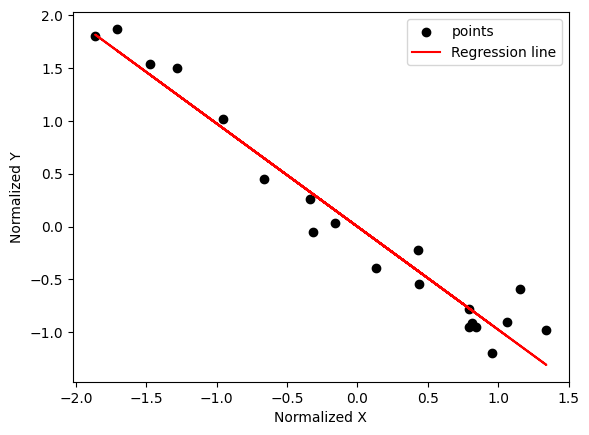

In [3]:
#matrix [1, X] for linear regression
X_matrix = np.vstack((np.ones(len(X_norm)), X_norm))

# closed form is b = (X^T*X)^-1 * X^T*Y, so (X^T*X) * b = X^T*Y
# therefore we solve for b using np.linalg.solve
theta = np.linalg.solve(X_matrix @ X_matrix.T, X_matrix @ Y_norm)
print(f"slope: {theta[1]}, intercept: {theta[0]}")

#data regression line and data points
plt.scatter(X_norm, Y_norm, color='black', label='points')
plt.plot(X_norm, X_matrix.T @ theta, color='red', label='Regression line')
plt.xlabel('Normalized X')
plt.ylabel('Normalized Y')
plt.legend()
plt.show()

### A.I.4 — Gradient descent: cost function

Choose and motivate a cost function, compute its partial derivatives, and give the update rules.

In [ ]:
#We choose the mean squared error (MSE), which is smooth and convex in (θ0, θ1). It is sensetive to outliers, so larger prediction errors are punished more and parameters converge quicker

#cost function
loss_f = lambda slope, intercept: (((X_norm * slope + intercept) - Y_norm)**2).mean()


#partial derivatives
part_der_slope = lambda slope, intercept: (2 * ((X_norm * slope + intercept) - Y_norm) * X_norm).mean()
part_der_intercept = lambda slope, intercept: (2 * ((X_norm * slope + intercept) - Y_norm)).mean()


#update rules 
lr = 0.01
slope_example = 0
intercept_example = 0
slope_delta_example = part_der_slope(slope_example, intercept_example)
intercept_delta_example = part_der_intercept(slope_example, intercept_example)
slope_example -= lr * slope_delta_example
intercept_example -= lr * intercept_delta_example

### A.I.5 — First gradient descent iteration

Initialize the parameters randomly, report the learning rate and first update, and plot the fitted line.

Initial slope: 1.764052345967664, intercept: 0.4001572083672233, loss: 7.712519178917366
Iteration 1: slope: 1.2162072613864674, intercept: 0.3201257666937779, loss: 4.953665763712388


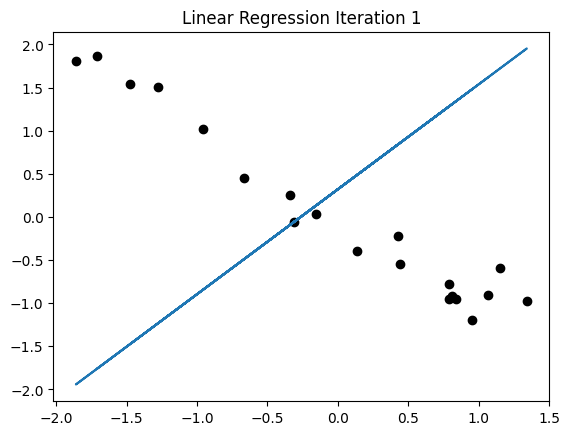

In [5]:
#random initialization

np.random.seed(0)
slope = np.random.normal()
intercept = np.random.normal()
print(f"Initial slope: {slope}, intercept: {intercept}, loss: {loss_f(slope, intercept)}")
lr = 0.1

color = cycle(plt.get_cmap("tab20").colors)
linreg_iterations = [0]
linreg_loss_history = [loss_f(slope, intercept)]

#first iteration

for i in range(1):

    slope_delta = part_der_slope(slope, intercept)
    intercept_delta = part_der_intercept(slope, intercept)

    slope -= lr * slope_delta
    intercept -= lr * intercept_delta
    loss = loss_f(slope, intercept)
    linreg_iterations.append(i+1)
    linreg_loss_history.append(loss)
    print(f"Iteration {i+1}: slope: {slope}, intercept: {intercept}, loss: {loss}")

    #plot regression line and data points
    plt.scatter(X_norm, Y_norm, color='black', label='points')
    plt.plot(X_norm, X_matrix.T @ np.array([intercept, slope]), color=next(color), label='Regression line')
    plt.title(f"Linear Regression Iteration {i+1}")

plt.show()



### A.I.6 — Second gradient descent iteration

Perform the second update, report the new parameters, and plot the fitted line.

Iteration 2: slope: 0.77793119372151, intercept: 0.25610061335502166, loss: 3.187999577981203


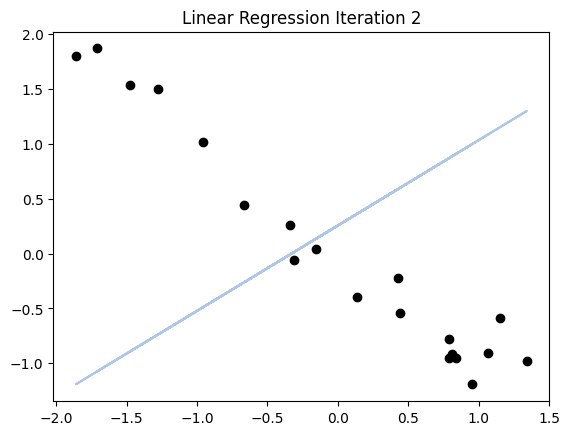

In [6]:
for i in range(1,2):
    slope_delta = part_der_slope(slope, intercept)
    intercept_delta = part_der_intercept(slope, intercept)

    slope -= lr * slope_delta
    intercept -= lr * intercept_delta
    loss = loss_f(slope, intercept)
    linreg_iterations.append(i+1)
    linreg_loss_history.append(loss)
    print(f"Iteration {i+1}: slope: {slope}, intercept: {intercept}, loss: {loss}")

    #plot regression line and data points
    plt.scatter(X_norm, Y_norm, color='black', label='points')
    plt.plot(X_norm, X_matrix.T @ np.array([intercept, slope]), color=next(color), label='Regression line')
    plt.title(f"Linear Regression Iteration {i+1}")

### A.I.7 — Final gradient descent iteration

Continue optimizing, report the final parameters, and plot the regression line and cost history.

Iteration 3: slope: 0.4273103395895441, intercept: 0.20488049068401668, loss: 2.0579732191132436
Iteration 4: slope: 0.14681365628397142, intercept: 0.1639043925472127, loss: 1.3347563494377503
Iteration 5: slope: -0.07758369036048679, intercept: 0.13112351403776956, loss: 0.8718975528454344
Iteration 6: slope: -0.2571015676760533, intercept: 0.10489881123021505, loss: 0.5756679230263522
Iteration 7: slope: -0.4007158695285065, intercept: 0.08391904898417145, loss: 0.3860809599421396
Iteration 8: slope: -0.5156073110104691, intercept: 0.06713523918733658, loss: 0.26474530356824355
Iteration 9: slope: -0.6075204641960392, intercept: 0.05370819134986869, loss: 0.18709048348895
Iteration 10: slope: -0.6810509867444953, intercept: 0.04296655307989438, loss: 0.13739139863820213
Iteration 11: slope: -0.7398754047832601, intercept: 0.03437324246391494, loss: 0.10558398433372354
Iteration 12: slope: -0.7869349392142719, intercept: 0.027498593971131396, loss: 0.08522723917885722
Iteration 13: s

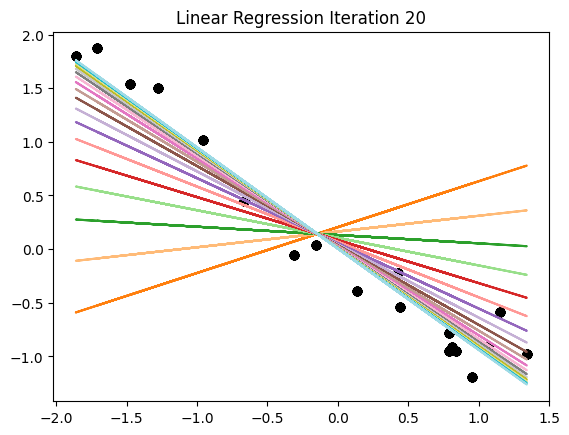

Text(0, 0.5, 'Loss')

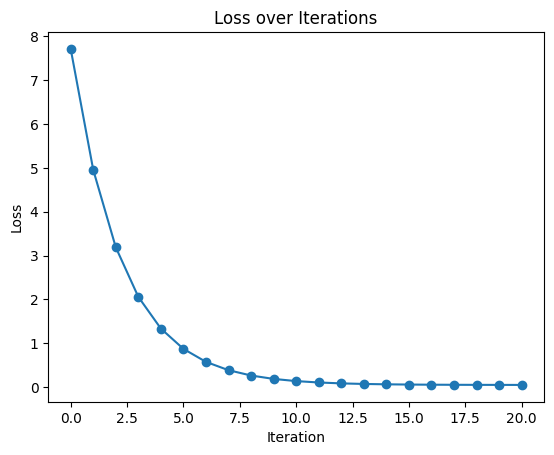

In [7]:
plt.show()

for i in range(2, 20):
    slope_delta = part_der_slope(slope, intercept)
    intercept_delta = part_der_intercept(slope, intercept)

    slope -= lr * slope_delta
    intercept -= lr * intercept_delta
    loss = loss_f(slope, intercept)
    linreg_iterations.append(i+1)
    linreg_loss_history.append(loss)
    print(f"Iteration {i+1}: slope: {slope}, intercept: {intercept}, loss: {loss}")

    #plot regression line and data points
    plt.scatter(X_norm, Y_norm, color='black', label='points')
    plt.plot(X_norm, X_matrix.T @ np.array([intercept, slope]), color=next(color), label='Regression line')
    plt.title(f"Linear Regression Iteration {i+1}")

plt.show()

plt.plot(linreg_iterations, linreg_loss_history, marker='o')
plt.title("Loss over Iterations")
plt.xlabel("Iteration")
plt.ylabel("Loss")



### A.I.8 — Discussion

Compare least squares and gradient-descent linear regression.

In [8]:
loss_squared = loss_f(theta[1], theta[0])
loss_gradient_descent = loss_f(slope, intercept)
print(f"Loss from closed form: {loss_squared}, Loss from gradient descent: {loss_gradient_descent}")

#full discussion is in the report.


Loss from closed form: 0.04903747001465038, Loss from gradient descent: 0.05005612145791629


### A.II.1 — Polynomial regression: derivatives

Derive the partial derivatives of the specified polynomial regression loss.

In [9]:

#We will use the data from A.I.2 as z-score is especially suitable for polynomial regression - besides stated benefits it also prevent overflow due to the exponentiation

cost_f_poly = lambda theta2, theta1, theta0: (((theta2 * X_norm**2 + theta1 * X_norm + theta0) - Y_norm)**4).mean() / 4
part_der_theta2 = lambda theta2, theta1, theta0: (X_norm**2 * ((theta2 * X_norm**2 + theta1 * X_norm + theta0) - Y_norm)**3).mean()
part_der_theta1 = lambda theta2, theta1, theta0: (X_norm * ((theta2 * X_norm**2 + theta1 * X_norm + theta0) - Y_norm)**3).mean()
part_der_theta0 = lambda theta2, theta1, theta0: (((theta2 * X_norm**2 + theta1 * X_norm + theta0) - Y_norm)**3).mean()

### A.II.2 — Polynomial regression: update rules

Give the gradient descent update rule for each parameter.

In [10]:
lr_poly = 0.01
theta2_example, theta1_example, theta0_example = 0, 0, 0
theta_2_delta_example = part_der_theta2(theta2_example, theta1_example, theta0_example)
theta_1_delta_example = part_der_theta1(theta2_example, theta1_example, theta0_example)
theta_0_delta_example = part_der_theta0(theta2_example, theta1_example, theta0_example)
theta2_example -= lr_poly * theta_2_delta_example
theta1_example -= lr_poly * theta_1_delta_example
theta0_example -= lr_poly * theta_0_delta_example

### A.II.3 — Polynomial regression: training

Plot how the polynomial fit changes over iterations and report the initialization and learning rate.

Initial theta2: 0.9787379841057392, theta1: 2.240893199201458, theta0: 1.8675579901499675
Iteration 1: theta2: -1.0288837520736123, theta1: 0.37161339791886827, theta0: 0.025373459562307632, loss: 34.81794746619847
Iteration 2: theta2: 0.4816046594970178, theta1: -0.5137259892836623, theta0: 0.5512160606329672, loss: 0.5526183961288011
Iteration 3: theta2: 0.44239990845441607, theta1: -0.5310642091123249, theta0: 0.5193711837160029, loss: 0.42421425666104495
Iteration 4: theta2: 0.41159755226533085, theta1: -0.5461882361895547, theta0: 0.4933352902978372, loss: 0.3393186321736724
Iteration 5: theta2: 0.386473619421738, theta1: -0.5595247519824494, theta0: 0.4713786796610359, loss: 0.2795537883075114
Iteration 6: theta2: 0.3654242329285577, theta1: -0.5714058587606468, theta0: 0.45244440467106345, loss: 0.2355330798110291
Iteration 7: theta2: 0.34742722089108213, theta1: -0.582086464539597, theta0: 0.4358375601463528, loss: 0.20197441129425636
Iteration 8: theta2: 0.3317927153444154, th

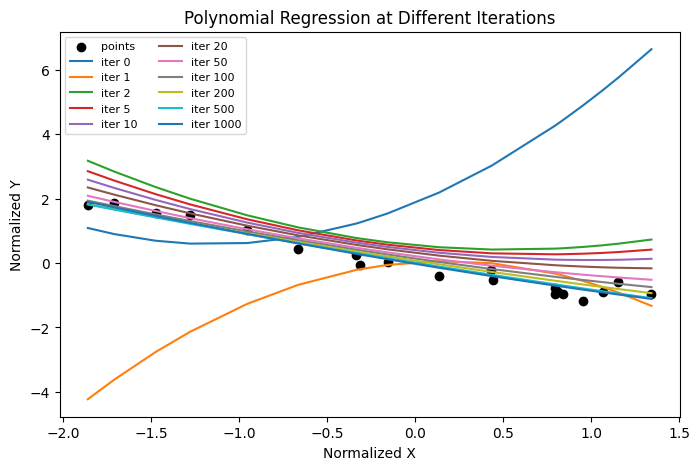

In [11]:
theta2 = np.random.normal()
theta1 = np.random.normal()
theta0 = np.random.normal()
lr_poly = 0.02

initial_theta2, initial_theta1, initial_theta0 = theta2, theta1, theta0
print(f"Initial theta2: {theta2}, theta1: {theta1}, theta0: {theta0}")

color = cycle(plt.get_cmap("tab20").colors)
#plt.cla()

plot_step = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
poly_loss_history = [cost_f_poly(theta2, theta1, theta0)]
poly_iterations = [0]
poly_snapshots = {0: (theta2, theta1, theta0)}

for i in range(1, 1001):
    theta_2_delta = part_der_theta2(theta2, theta1, theta0)
    theta_1_delta = part_der_theta1(theta2, theta1, theta0)
    theta_0_delta = part_der_theta0(theta2, theta1, theta0)
    theta2 -= lr_poly * theta_2_delta
    theta1 -= lr_poly * theta_1_delta
    theta0 -= lr_poly * theta_0_delta
    loss = cost_f_poly(theta2, theta1, theta0)
    poly_loss_history.append(loss)
    poly_iterations.append(i)
    print(f"Iteration {i}: theta2: {theta2}, theta1: {theta1}, theta0: {theta0}, loss: {loss}")

    if(i in plot_step):
        poly_snapshots[i] = (theta2, theta1, theta0)


X_sorted = np.sort(X_norm)

# Fig5: polynomial regression for different iterations
plt.figure(figsize=(8, 5))
plt.scatter(X_norm, Y_norm, color='black', label='points')
for step in plot_step:
    t2, t1, t0 = poly_snapshots[step]
    plt.plot(X_sorted, t2 * X_sorted**2 + t1 * X_sorted + t0, label=f'iter {step}')
plt.xlabel('Normalized X')
plt.ylabel('Normalized Y')
plt.title('Polynomial Regression at Different Iterations')
plt.legend(fontsize=8, ncol=2)
plt.savefig('fig5.png', bbox_inches='tight')

### A.II.4 — Discussion

Discuss the similarities and differences between linear and polynomial regression.

In [12]:
loss_squared_poly = lambda theta2, theta1, theta0: (((theta2 * X_norm**2 + theta1 * X_norm + theta0) - Y_norm)**2).mean() 

print(f"Loss from closed form linear regression: {loss_squared}")
print(f"Loss from linear regression: {loss_gradient_descent}")
print(f"Loss from polynomial regression: {loss_squared_poly(theta2, theta1, theta0)}")

#full discussion is in the report!


Loss from closed form linear regression: 0.04903747001465038
Loss from linear regression: 0.05005612145791629
Loss from polynomial regression: 0.04094737797354426


### Polynomial figures for the report (special section just to get additional figures)

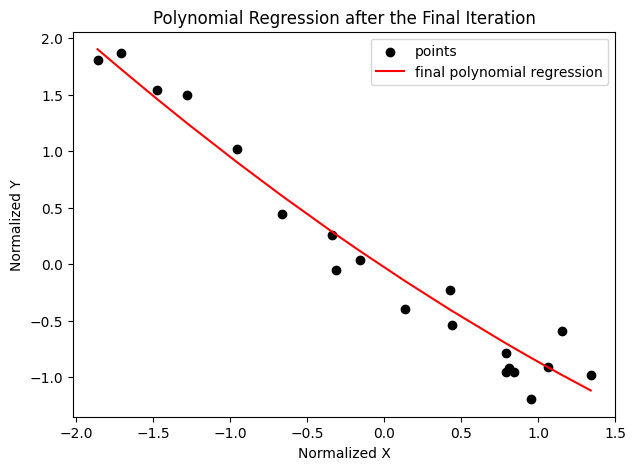

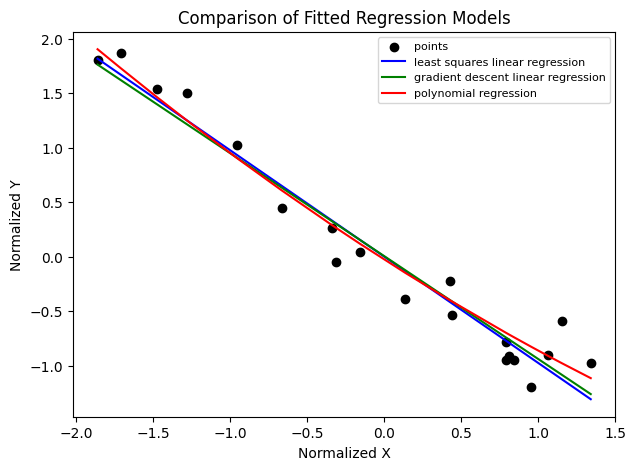

In [13]:
# Fig6: final polynomial regression line
plt.figure(figsize=(7, 5))
plt.scatter(X_norm, Y_norm, color='black', label='points')
plt.plot(X_sorted, theta2 * X_sorted**2 + theta1 * X_sorted + theta0, color='red', label='final polynomial regression')
plt.xlabel('Normalized X')
plt.ylabel('Normalized Y')
plt.title('Polynomial Regression after the Final Iteration')
plt.legend()
plt.savefig('fig6.png', bbox_inches='tight')
plt.show()

# Figure 7: comparison of linear and polynomial regression models
plt.figure(figsize=(7, 5))
plt.scatter(X_norm, Y_norm, color='black', label='points')
plt.plot(X_sorted, X_sorted * theta[1] + theta[0], color='blue', label='least squares linear regression')
plt.plot(X_sorted, X_sorted * slope + intercept, color='green', label='gradient descent linear regression')
plt.plot(X_sorted, theta2 * X_sorted**2 + theta1 * X_sorted + theta0, color='red', label='polynomial regression')
plt.xlabel('Normalized X')
plt.ylabel('Normalized Y')
plt.title('Comparison of Fitted Regression Models')
plt.legend(fontsize=8)
plt.savefig('fig7.png', bbox_inches='tight')
plt.show()